[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Graf_et_al_2019/figure_4.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/sandbox/Graf_et_al_2019/figure_4.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Graf_et_al_2019/figure_4.ipynb)

based on [Graf et al. 2019](https://doi.org/10.5194/acp-19-747-2019)

In [1]:
import os, sys
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
import math
import numpy as np
from matplotlib import pyplot
from scipy.interpolate import CubicSpline

from open_atmos_jupyter_utils import show_plot
from PySDM.physics import si, in_unit
from PySDM.environments import Parcel
from PySDM.backends import CPU
from PySDM import Particulator, Formulae
from PySDM.dynamics import AmbientThermodynamics, Condensation
from PySDM.initialisation.spectra import Lognormal
from PySDM.initialisation.sampling import spectral_sampling
from PySDM.initialisation.hygroscopic_equilibrium import equilibrate_wet_radii
from PySDM.initialisation import discretise_multiplicities
from PySDM import products

In [3]:
formulae = Formulae(
    isotope_equilibrium_fractionation_factors="Majoube1971+MerlivatAndNief1967+Majoube1970",
    isotope_kinetic_fractionation_factors="JouzelAndMerlivat1984",
    isotope_diffusivity_ratios="Stewart1975",
    isotope_meteoric_water_line="Dansgaard1964",
)
const = formulae.constants
pvs_water = formulae.saturation_vapour_pressure.pvs_water

RH0 = 0.75
p0 = 950 * si.hPa
T0 = const.T0 + 12 * si.K

delta0_2H = -150 * const.PER_MILLE
R0_2H = formulae.trivia.isotopic_delta_2_ratio(
    delta0_2H, const.VSMOW_R_2H
)
delta0_18O = formulae.isotope_meteoric_water_line.d18O_of_d2H(delta0_2H)
R0_18O = formulae.trivia.isotopic_delta_2_ratio(
    delta0_18O,
    const.VSMOW_R_18O,
)

alt_initial = 500 * si.m
alt_final = 3500 * si.m

total_displacement = alt_final - alt_initial
initial_water_vapour_mixing_ratio = const.eps / (p0 / RH0 / pvs_water(T0) - 1)

n_sd = 1
dt = 10 * si.s
vertical_velocity = 2.5 * si.m / si.s

In [4]:
env = Parcel(
    # given in the paper
    p0=p0,
    T0=T0,
    initial_water_vapour_mixing_ratio=initial_water_vapour_mixing_ratio,
    # arbitrary choices
    w=vertical_velocity,
    dt=dt,
    mass_of_dry_air=1e3 * si.kg,
    backend=CPU(formulae=formulae)
)

In [5]:
spectrum = Lognormal(norm_factor=1e4 / si.mg, m_mode=50 * si.nm, s_geom=1.5)
kappa = 0.5 * si.dimensionless
cloud_range = (0.5 * si.um, 25 * si.um)
output_interval = 4
output_points = 40

In [6]:
r_dry, specific_concentration = spectral_sampling.Logarithmic(
    spectrum
).sample_deterministic(n_sd)

In [7]:
v_dry = formulae.trivia.volume(radius=r_dry)

In [8]:
r_wet = equilibrate_wet_radii(
    r_dry=r_dry,
    environment=env,
    kappa_times_dry_volume=kappa * v_dry,
)

In [9]:
attributes = {
    "multiplicity": discretise_multiplicities(
        specific_concentration * env.mass_of_dry_air
    ),
    "dry volume": v_dry,
    "kappa times dry volume": kappa * v_dry,
    "volume": formulae.trivia.volume(radius=r_wet),
}

In [10]:
particulator = Particulator(
    n_sd=n_sd, environment=env,dynamics=(AmbientThermodynamics(), Condensation()),
    attributes=attributes,
    products=(
        products.PeakSaturation(name="S_max"),
        products.ParcelDisplacement(name="z"),
        products.AmbientTemperature(name="T"),
        products.AmbientWaterVapourMixingRatio(
            name="w", var="water_vapour_mixing_ratio"
        ),
    ),
)

In [11]:
n_steps = total_displacement / (dt * vertical_velocity)

output = {name: [] for name in particulator.products}
levels = {"CB": None, "0C": None}

ONE_AND_ONLY_GRID_ELEMENT = 0

for step in range(math.ceil(n_steps)):
    particulator.advance(n_steps=1)
    for name, product in particulator.products.items():
        product_buffer_reference = product.get()
        output[name].append(product_buffer_reference[ONE_AND_ONLY_GRID_ELEMENT])

    if levels["CB"] is None and output["S_max"][-1] > 1:
        levels["CB"] = 0.5 * (output["z"][-1] + output["z"][-2])

    if levels["0C"] is None and output["T"][-1] < const.T0:
        levels["0C"] = 0.5 * (output["z"][-1] + output["z"][-2])

In [12]:
specific_humidity = formulae.trivia.mixing_ratio_to_specific_content(
    np.asarray(output["w"])
)

T = np.asarray(output["T"])
S_max = np.asarray(output["S_max"])

tmax = 273.15 * si.K
tmin = 250.15 * si.K
lam = 0.004
fc_interpolation = CubicSpline((tmin, tmax), (0.0, 1.0), bc_type=((1, 0.0), (1, 0.0)))
Si_interpolation = CubicSpline((tmin, tmax), (1 - lam * (tmin - 273.15 * si.K), 1.0), bc_type=((1, -lam), (1, 0.0)))


def interpolation(t):
    if t <= tmin:
        fc = 0.0
        Si = 1 - lam * (t - 273.15 * si.K)
    elif t >= tmax:
        fc = 1.0
        Si = 1.0
    else:
        fc = fc_interpolation(t)
        Si = Si_interpolation(t)
    return fc, Si


def Rayleigh_distillation(R_init, a_liq, a_ice, a_kin=None, Ts=T, q=specific_humidity):
    R = np.full_like(q, np.nan)
    R[0] = R_init
    for i in range(1, len(q)):
        T_mid = (Ts[i] + Ts[i - 1]) / 2
        fc_mid, Si_mid = interpolation(T_mid)
        if a_kin:
            kin = a_kin(
                a_ice(T_mid),
                Si_mid,
                formulae.isotope_diffusivity_ratios.ratio_2H_heavy_to_light(T_mid),
            )
        else:
            kin = 1
        a_eff = fc_mid * a_liq(T_mid) + (1 - fc_mid) * a_ice(T_mid) * kin
        R[i] = R[i - 1] * (q[i] / q[i - 1]) ** (a_eff - 1)
    return R


deltas_Rayleigh = {'2H': {}, '18O': {}}
for iso in ("2H", "18O"):
    a_eql_l = getattr(formulae.isotope_equilibrium_fractionation_factors, f"alpha_l_{iso}")
    a_eql_i = getattr(formulae.isotope_equilibrium_fractionation_factors, f"alpha_i_{iso}")
    r0 = R0_2H if iso == "2H" else R0_18O
    vsmow = getattr(const, f"VSMOW_R_{iso}")
    deltas_Rayleigh[iso]['eql'] = formulae.trivia.isotopic_ratio_2_delta(
        Rayleigh_distillation(r0, a_eql_l, a_eql_i), vsmow
    )
    deltas_Rayleigh[iso]['kin'] = formulae.trivia.isotopic_ratio_2_delta(
        Rayleigh_distillation(
            r0,
            a_eql_l,
            a_eql_i,
            formulae.isotope_kinetic_fractionation_factors.alpha_kinetic,
        ),
        vsmow,
    )

d_excess = formulae.isotope_meteoric_water_line.excess_d(
    deltas_Rayleigh["2H"]['eql'], deltas_Rayleigh["18O"]['eql']
)

z = np.asarray(output["z"]) + alt_initial

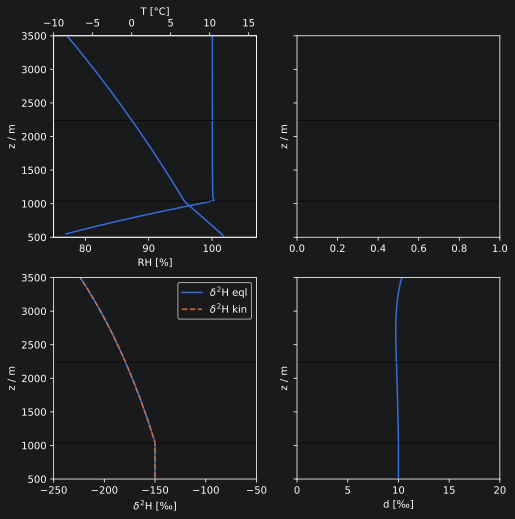

In [13]:
fig, axs = pyplot.subplots(2, 2, squeeze=False, figsize=(8, 8), sharey=True)
xya1 = axs[0, 0]
xya2 = xya1.twiny()

xya1.plot(in_unit(S_max, const.PER_CENT), z)
xya2.plot(T - const.T0, z)

xya1.set_xlim(75, 107)
xya2.set_xlim(-10, 16)
xya1.set_ylim(alt_initial, alt_final)
xya1.set_xlabel("RH [%]")
xya2.set_xlabel("T [°C]")


xyc = axs[1, 0]
xlabel = "$\\delta^2\\mathrm{H}$"
for delta_2H, label, ls in zip(
    (deltas_Rayleigh['2H']['eql'], deltas_Rayleigh['2H']['kin']),
    (f"{xlabel} eql", f"{xlabel} kin"),
    ("-", "--"),
):
    xyc.plot(in_unit(delta_2H, const.PER_MILLE), z, label=label, ls=ls)

xyc.set_xlabel(f"{xlabel} [‰]")
xyc.set_xlim(-250, -50)
xyc.legend()

xyd = axs[1, 1]
xyd.plot(in_unit(d_excess, const.PER_MILLE), z)
xyd.set_xlabel("d [‰]")
xyd.set_xlim(0, 20)

for ax in axs.flat:
    ax.set_ylabel("z / m")
    for level in levels.values():
        ax.axhline(y=level + alt_initial, ls="--", color="black", lw=0.8)

show_plot("fig_4.pdf")